<a href="https://colab.research.google.com/github/Faiva-404/PemMes-Ganjil-2026/blob/main/JS11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **ANN (Artificial Neural Network)**

Contoh Persamaan

In [1]:
#Contoh code Perceptron sederhana
import numpy as np

# Data input (X) dan target (y)
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([0,0,0,1])  # AND gate

# Inisialisasi bobot dan bias
w = np.random.rand(2)
b = np.random.rand(1)
lr = 0.1  # learning rate

# Fungsi aktivasi (step function)
def activation(x):
    return 1 if x >= 0 else 0

# Training
for epoch in range(10):
    for i in range(len(X)):
        z = np.dot(X[i], w) + b
        y_pred = activation(z)
        error = y[i] - y_pred
        # Update bobot
        w += lr * error * X[i]
        b += lr * error
    print(f"Epoch {epoch+1}, bobot: {w}, bias: {b}")

Epoch 1, bobot: [0.64758112 0.38422852], bias: [0.3357692]
Epoch 2, bobot: [0.54758112 0.28422852], bias: [0.0357692]
Epoch 3, bobot: [0.44758112 0.18422852], bias: [-0.2642308]
Epoch 4, bobot: [0.34758112 0.18422852], bias: [-0.3642308]
Epoch 5, bobot: [0.34758112 0.18422852], bias: [-0.3642308]
Epoch 6, bobot: [0.34758112 0.18422852], bias: [-0.3642308]
Epoch 7, bobot: [0.34758112 0.18422852], bias: [-0.3642308]
Epoch 8, bobot: [0.34758112 0.18422852], bias: [-0.3642308]
Epoch 9, bobot: [0.34758112 0.18422852], bias: [-0.3642308]
Epoch 10, bobot: [0.34758112 0.18422852], bias: [-0.3642308]




> Praktikum 1



In [2]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.311320696379949
Epoch 1000, Loss: 0.22144963444463198
Epoch 2000, Loss: 0.1715420424179419
Epoch 3000, Loss: 0.07336207237178717
Epoch 4000, Loss: 0.020815629592993396
Epoch 5000, Loss: 0.010159846697282881
Epoch 6000, Loss: 0.006420166404859276
Epoch 7000, Loss: 0.004607837474611189
Epoch 8000, Loss: 0.003560208704306354
Epoch 9000, Loss: 0.002884965972705434
Prediksi:
[[0.04287971]
 [0.94874436]
 [0.94890596]
 [0.05090607]]


Tugas 1

In [3]:
import numpy as np

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Fungsi aktivasi Sigmoid
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Fungsi untuk training ANN
def training_ann(hidden_size, activation='sigmoid'):

    np.random.seed(42)

    input_size = 2
    output_size = 1
    lr = 0.1

    # Inisialisasi bobot
    W1 = np.random.randn(input_size, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size)
    b2 = np.zeros((1, output_size))

    # Training
    for epoch in range(10000):

        # Forward pass
        z1 = np.dot(X, W1) + b1

        if activation == 'sigmoid':
            a1 = sigmoid(z1)
        else:
            a1 = np.maximum(0, z1)

        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)

        # Hitung error
        error = y - a2

        # Backpropagation output layer
        d_a2 = error * a2 * (1 - a2)

        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        # Backpropagation hidden layer
        if activation == 'sigmoid':
            turunan = a1 * (1 - a1)
        else:
            turunan = (z1 > 0).astype(float)

        d_a1 = np.dot(d_a2, W2.T) * turunan

        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    # Menghitung prediksi akhir
    z1 = np.dot(X, W1) + b1

    if activation == 'sigmoid':
        a1 = sigmoid(z1)
    else:
        a1 = np.maximum(0, z1)

    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    loss = np.mean(np.square(y - a2))

    return loss, a2


# Model awal: 2 neuron, Sigmoid
loss_awal, prediksi_awal = training_ann(2, 'sigmoid')

# Model baru: 3 neuron, Sigmoid
loss_3_neuron, prediksi_3_neuron = training_ann(3, 'sigmoid')

print("Loss Model Awal (2 Neuron):", loss_awal)
print("Loss Model 3 Neuron:", loss_3_neuron)

print("\nPrediksi Model 3 Neuron:")
print(prediksi_3_neuron)

Loss Model Awal (2 Neuron): 0.12822604512027116
Loss Model 3 Neuron: 0.0022970292561724902

Prediksi Model 3 Neuron:
[[0.02515318]
 [0.95264015]
 [0.95122762]
 [0.06271949]]




> Praktikum 2



In [5]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model.fit(X_train, y_train, epochs=50, batch_size=8)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3583 - loss: 1.3452
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3583 - loss: 1.2607 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3583 - loss: 1.1803 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3583 - loss: 1.1200 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3583 - loss: 1.0705 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3583 - loss: 1.0263 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3667 - loss: 0.9839 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4750 - loss: 0.9416 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5833 - loss: 0.9057 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7000 - loss: 0.8746 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6667 - loss: 0.8482 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0

Tugas 2
* Ubah jumlah neuron hidden layer.
* Bandingkan akurasi dengan konfigurasi awal.

In [6]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=iris.target)

# Fungsi untuk membuat dan melatih model
def buat_model(neuron1, neuron2):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(neuron1, activation='relu'),
        tf.keras.layers.Dense(neuron2, activation='relu'),
        tf.keras.layers.Dense(3, activation='softmax')])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'])

    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=8,
        verbose=0)

    loss, accuracy = model.evaluate(
        X_test, y_test, verbose=0)
    return loss, accuracy


# Model awal: 10 dan 8 neuron
loss_awal, acc_awal = buat_model(10, 8)

# Model modifikasi: 16 dan 12 neuron
loss_modifikasi, acc_modifikasi = buat_model(16, 12)


# Menampilkan hasil
hasil_tugas2 = pd.DataFrame({
    'Model': ['Model Awal', 'Model Modifikasi'],
    'Hidden Layer 1': [10, 16],
    'Hidden Layer 2': [8, 12],
    'Loss': [loss_awal, loss_modifikasi],
    'Akurasi': [acc_awal, acc_modifikasi]})

print("HASIL PERBANDINGAN JUMLAH NEURON")
print(hasil_tugas2.to_string(index=False))

HASIL PERBANDINGAN JUMLAH NEURON
           Model  Hidden Layer 1  Hidden Layer 2     Loss  Akurasi
      Model Awal              10               8 0.221645 1.000000
Model Modifikasi              16              12 0.328141 0.966667


Tugas 3


* Bandingkan Sigmoid vs ReLU pada dataset Iris.
* Catat perbedaan loss dan akurasi.



In [7]:
import tensorflow as tf
import pandas as pd

# Fungsi untuk membuat dan melatih model
def model_aktivasi(aktivasi):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(10, activation=aktivasi),
        tf.keras.layers.Dense(8, activation=aktivasi),
        tf.keras.layers.Dense(3, activation='softmax')])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'])

    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=8,
        verbose=0)

    loss, accuracy = model.evaluate(
        X_test, y_test, verbose=0)
    return loss, accuracy


# Model dengan aktivasi Sigmoid
loss_sigmoid, acc_sigmoid = model_aktivasi('sigmoid')

# Model dengan aktivasi ReLU
loss_relu, acc_relu = model_aktivasi('relu')


# Menampilkan hasil perbandingan
hasil_tugas3 = pd.DataFrame({
    'Fungsi Aktivasi': ['Sigmoid', 'ReLU'],
    'Loss': [loss_sigmoid, loss_relu],
    'Akurasi': [acc_sigmoid, acc_relu]})

print("HASIL PERBANDINGAN FUNGSI AKTIVASI")
print(hasil_tugas3.to_string(index=False))

HASIL PERBANDINGAN FUNGSI AKTIVASI
Fungsi Aktivasi     Loss  Akurasi
        Sigmoid 0.575750 0.766667
           ReLU 0.221645 1.000000




> Praktikum 3



In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 770ms/step - loss: 2.6202
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 2.5910
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 2.5620
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 2.5333
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 2.5049
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 2.4767
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 2.4488
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 2.4212
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 2.3939
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 2.3669
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 2.3401
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - loss: 2.3136
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 2.2875
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 2.2616
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 2.2360
Epoch 16/100
1/1 ━━━━━━━━━━━━

Tugas 4
* Ubah learning rate.
* Bandingkan hasil loss.

In [9]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Membuat dataset dummy
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]})

X = data[['luas']]
y = data[['harga']]

# 2. Normalisasi data
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

# 3. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42)

# 4. Fungsi membuat dan melatih model
def training_model(learning_rate):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='mse')

    history = model.fit(
        X_train, y_train,
        epochs=100,
        verbose=0)

    loss = model.evaluate(X_test, y_test, verbose=0)

    return loss, history

# 5. Percobaan tiga learning rate
lr_1 = 0.001
lr_2 = 0.01
lr_3 = 0.0001

loss_1, history_1 = training_model(lr_1)
loss_2, history_2 = training_model(lr_2)
loss_3, history_3 = training_model(lr_3)

# 6. Menampilkan hasil perbandingan
hasil = pd.DataFrame({
    'Learning Rate': [lr_1, lr_2, lr_3],
    'Loss Testing': [loss_1, loss_2, loss_3]})

print("HASIL PERBANDINGAN LEARNING RATE")
print(hasil.to_string(index=False))

HASIL PERBANDINGAN LEARNING RATE
 Learning Rate  Loss Testing
        0.0010      0.477486
        0.0100      0.090521
        0.0001      0.905758


Praktikum berikut akan menggunakan data Boston untuk memprediksi harga rumah.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


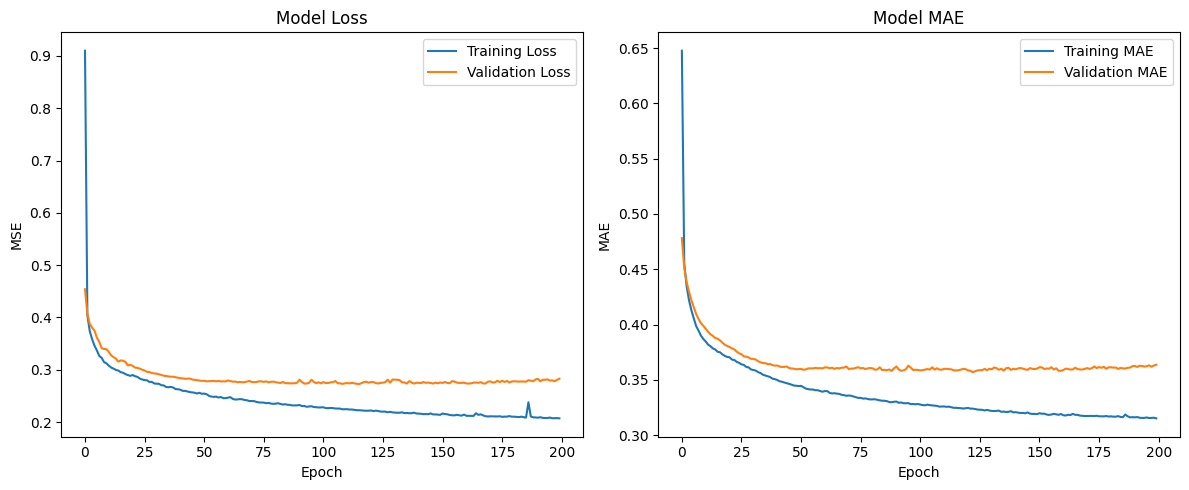

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 768us/step
RMSE: 0.5318386184621007
MAE: 0.36361260516351973


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Memuat dataset California Housing
data = fetch_california_housing()

X = data.data
y = data.target

# Normalisasi data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Membagi data training dan testing
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Membuat model ANN
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)])

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

# Training model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    verbose=0)

# Visualisasi Loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

# Visualisasi MAE
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()

# Prediksi
pred = model.predict(X_val)

# Evaluasi model
rmse = np.sqrt(mean_squared_error(y_val, pred))
mae = mean_absolute_error(y_val, pred)

print("RMSE:", rmse)
print("MAE:", mae)

Tugas Praktikum

In [15]:
import tensorflow as tf
import time
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Bangun model JST
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# 3. Kompilasi model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

# 4. Latih model
start_time = time.time()
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)
training_time = time.time() - start_time
print("Waktu pelatihan:", round(training_time, 2), "detik")

# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test)
print(f"Loss pada data uji: {loss:.4f}")
print(f"Akurasi pada data uji: {acc:.4f}")
print(f"Akurasi dalam persen: {acc * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8951 - loss: 0.3774 - val_accuracy: 0.9474 - val_loss: 0.1868
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9543 - loss: 0.1562 - val_accuracy: 0.9584 - val_loss: 0.1386
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9681 - loss: 0.1081 - val_accuracy: 0.9650 - val_loss: 0.1191
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9769 - loss: 0.0816 - val_accuracy: 0.9686 - val_loss: 0.1088
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9821 - loss: 0.0644 - val_accuracy: 0.9710 - val_loss: 0.1028
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9858 - loss: 0.0513 - val_accuracy: 0.9710 - val_loss: 0.1025
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9888 - loss: 0.0411 - val_accuracy: 0.9719 - val_loss: 0.1010
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9918 - loss: 0.0327 - val_accuracy: 0.